# Customer Segmentation: KMeans & DBSCAN

В этом проекте проводится сегментация клиентов интернет-магазина
по поведенческим, покупательским и социально-экономическим признакам.

Для кластеризации используются методы KMeans и DBSCAN.
Перед кластеризацией данные подготавливаются, стандартизируются
и преобразуются методом PCA.

Загружаем данные

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/Customer Behavior Dataset.csv')

df.head()

,CustomerID,Age,Gender,Membership,Annual_Income_kUSD,Region,Platform,Product_Preference,Visits_per_Month,Time_Spent_per_Visit_min,Pages_Visited_per_Session,Previous_Purchases,Avg_Purchase_Value_USD,Total_Purchase_Value_USD,Days_Since_Last_Purchase,Made_Purchase_Last_Month,Will_Purchase_Next_Month,Next_Month_Spend_USD
0,1,40,Male,NaN,40.58,Central,Mobile,Apparel,5,6.0,5,1,NaN,42.43,0,0,0,0.0
1,2,33,Male,NaN,53.20,West,Mobile,Apparel,3,9.0,2,0,25.95,0.00,206,0,0,0.0
2,3,42,Female,NaN,73.70,West,Mobile,Home & Kitchen,3,13.9,2,0,71.06,13.92,15,0,0,0.0
3,4,51,Female,NaN,45.95,East,Mobile,Sports,3,1.0,4,1,35.81,91.43,149,0,0,0.0
4,5,32,Male,Premium,45.32,East,Mobile,Apparel,11,11.1,7,3,5.00,37.75,6,1,0,0.0


In [2]:
# Убираем идентификатор и целевую переменную из признаков для кластеризации
target = df['Made_Purchase_Last_Month'].copy()

X = df.drop(
    columns=[
        'CustomerID',
        'Made_Purchase_Last_Month'
    ]
).copy()

In [3]:
# Категориальные пропуски
X['Gender'] = X['Gender'].fillna('Unknown')
X['Membership'] = X['Membership'].fillna('Unknown')

# Для времени визита используем среднее
X['Time_Spent_per_Visit_min'] = (
    X['Time_Spent_per_Visit_min']
    .fillna(X['Time_Spent_per_Visit_min'].mean())
)

# Для среднего чека используем медиану
X['Avg_Purchase_Value_USD'] = (
    X['Avg_Purchase_Value_USD']
    .fillna(X['Avg_Purchase_Value_USD'].median())
)

print('Количество пропусков:', X.isna().sum().sum())

Количество пропусков: 0


In [4]:
categorical_columns = [
    'Gender',
    'Membership',
    'Region',
    'Platform',
    'Product_Preference'
]

X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print('Размер после кодирования:', X_encoded.shape)

Размер после кодирования: (1000, 26)


In [5]:
selected_features = [
    'Membership_Premium',
    'Membership_Unknown',
    'Visits_per_Month',
    'Pages_Visited_per_Session',
    'Time_Spent_per_Visit_min',
    'Previous_Purchases',
    'Avg_Purchase_Value_USD',
    'Total_Purchase_Value_USD',
    'Annual_Income_kUSD',
    'Platform_Mobile'
]

X_selected = X_encoded[selected_features].copy()

X_selected.head()

,Membership_Premium,Membership_Unknown,Visits_per_Month,Pages_Visited_per_Session,Time_Spent_per_Visit_min,Previous_Purchases,Avg_Purchase_Value_USD,Total_Purchase_Value_USD,Annual_Income_kUSD,Platform_Mobile
0,0,1,5,5,6.0,1,35.665,42.43,40.58,1
1,0,1,3,2,9.0,0,25.950,0.00,53.20,1
2,0,1,3,2,13.9,0,71.060,13.92,73.70,1
3,0,1,3,4,1.0,1,35.810,91.43,45.95,1
4,1,0,11,7,11.1,3,5.000,37.75,45.32,1


In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_selected)

print('Размер данных после стандартизации:', X_scaled.shape)

Размер данных после стандартизации: (1000, 10)


In [9]:
pca = PCA(n_components=7)

X_pca = pca.fit_transform(X_scaled)

print(
    'Сохранённая доля дисперсии:',
    round(pca.explained_variance_ratio_.sum(), 3)
)

Сохранённая доля дисперсии: 0.897


In [10]:
X_pca_df = pd.DataFrame(
    X_pca,
    columns=[f'PC{i}' for i in range(1, 8)],
    index=df.index
)

X_pca_df.head()

,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-1.257480,-0.189362,0.528013,-0.039516,-0.176573,1.039915,0.188375
1,-1.972039,0.018173,0.449010,0.807883,0.192966,-0.228106,-0.349036
2,-1.058665,1.101515,0.143552,1.892612,0.737873,-0.734365,0.118849
3,-1.640567,0.648823,0.956474,-0.562658,-0.749267,1.113796,-0.464324
4,2.053469,-2.908738,0.202332,-0.220308,-0.380701,0.043647,0.427733


## Подготовка данных завершена

Для кластеризации использованы 10 признаков, описывающих:

- тип подписки;
- активность пользователя;
- историю покупок;
- средний и общий объём покупок;
- доход;
- используемую платформу.

Перед кластеризацией признаки были стандартизированы.

Для уменьшения размерности использован PCA:
7 главных компонент сохраняют около 89,7% исходной дисперсии.

## 2. Кластеризация методом KMeans

Сначала подбираю количество кластеров.

Для значений `K` от 2 до 10 сравниваю:
- inertia — насколько компактны кластеры;
- silhouette score — насколько хорошо объекты отделены от соседних кластеров.

Итоговое число кластеров выбирается с учётом как метрик, так и интерпретируемости сегментов.

Подбор числа кластеров K-means

In [14]:
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_pca_df)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_pca_df, labels)
    )

kmeans_metrics = pd.DataFrame({
    'Количество кластеров': list(k_values),
    'Инерция': inertia_values,
    'Silhouette': silhouette_values
})

display(
    kmeans_metrics.style.format({
        'Инерция': '{:.1f}',
        'Silhouette': '{:.3f}'
    })
)

,Количество кластеров,Инерция,Silhouette
0,2,6367.3,0.335
1,3,5564.8,0.179
2,4,4970.5,0.194
3,5,4497.8,0.197
4,6,4184.1,0.193
5,7,3978.8,0.196
6,8,3780.9,0.180
7,9,3627.8,0.176
8,10,3484.5,0.172


Графики

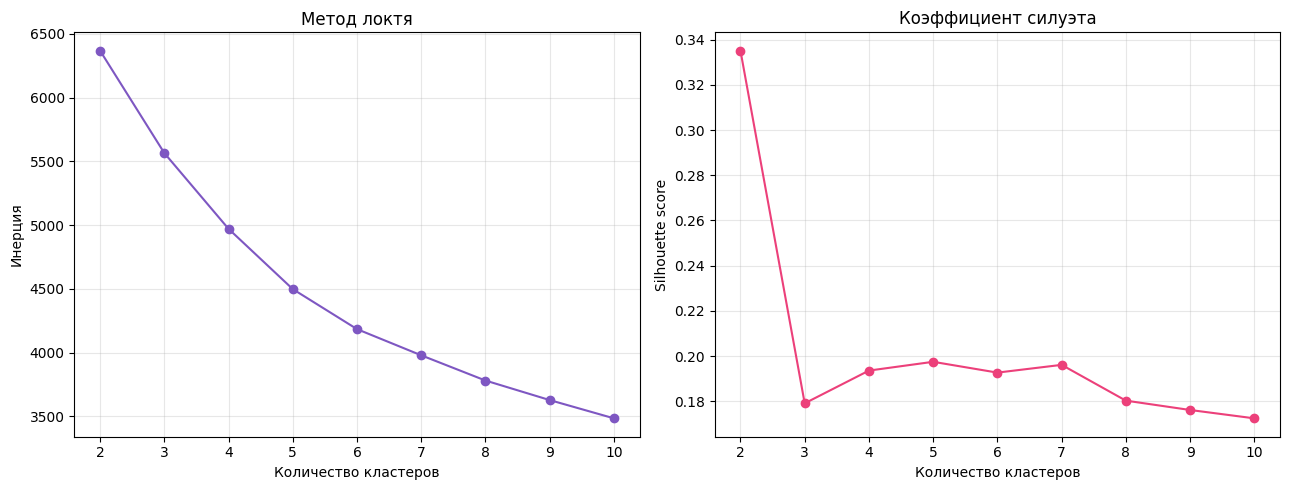

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    list(k_values),
    inertia_values,
    marker='o',
    color='#7E57C2'
)

axes[0].set_title('Метод локтя')
axes[0].set_xlabel('Количество кластеров')
axes[0].set_ylabel('Инерция')
axes[0].grid(alpha=0.3)

axes[1].plot(
    list(k_values),
    silhouette_values,
    marker='o',
    color='#EC407A'
)

axes[1].set_title('Коэффициент силуэта')
axes[1].set_xlabel('Количество кластеров')
axes[1].set_ylabel('Silhouette score')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Итоговая модель KMeans

In [16]:
# Итоговая модель KMeans
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans.fit_predict(X_pca_df)

# Добавляем номер кластера в исходную таблицу
df_kmeans = df.copy()
df_kmeans['KMeans_cluster'] = kmeans_labels

df_kmeans['KMeans_cluster'].value_counts().sort_index()

,count
KMeans_cluster,
0,309
1,241
2,76
3,236
4,138


График кластеров

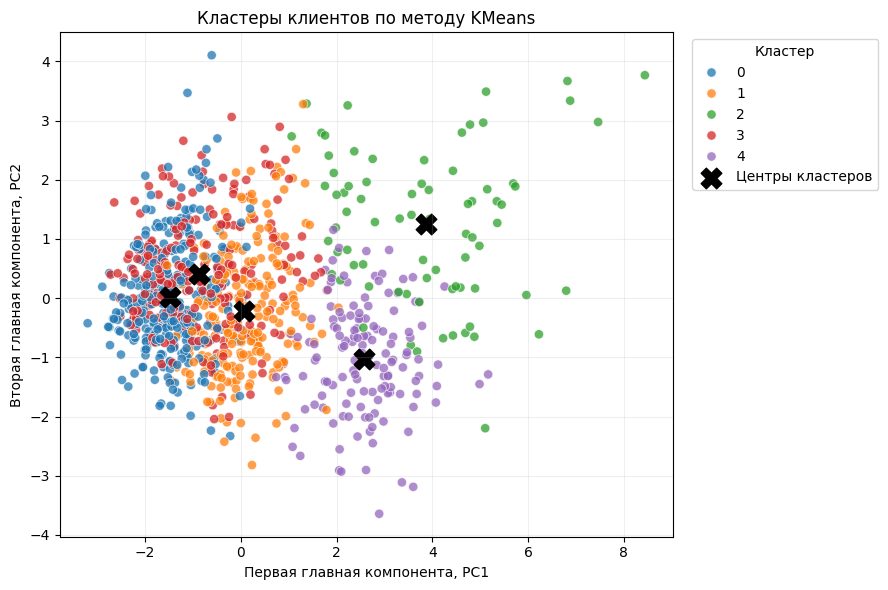

In [17]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca_df['PC1'],
    y=X_pca_df['PC2'],
    hue=kmeans_labels,
    palette='tab10',
    s=45,
    alpha=0.75
)

# Центры кластеров
centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='black',
    marker='X',
    s=220,
    label='Центры кластеров'
)

plt.title('Кластеры клиентов по методу KMeans')
plt.xlabel('Первая главная компонента, PC1')
plt.ylabel('Вторая главная компонента, PC2')
plt.legend(title='Кластер', bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Таблица с характеристиками кластеров

In [18]:
# На случай пропусков в исходной таблице
df_kmeans['Membership'] = df_kmeans['Membership'].fillna('Unknown')

df_kmeans['Time_Spent_per_Visit_min'] = (
    df_kmeans['Time_Spent_per_Visit_min']
    .fillna(df_kmeans['Time_Spent_per_Visit_min'].mean())
)

df_kmeans['Avg_Purchase_Value_USD'] = (
    df_kmeans['Avg_Purchase_Value_USD']
    .fillna(df_kmeans['Avg_Purchase_Value_USD'].median())
)

profile_columns = [
    'Annual_Income_kUSD',
    'Visits_per_Month',
    'Pages_Visited_per_Session',
    'Time_Spent_per_Visit_min',
    'Previous_Purchases',
    'Avg_Purchase_Value_USD',
    'Total_Purchase_Value_USD',
    'Made_Purchase_Last_Month'
]

cluster_profile = (
    df_kmeans
    .groupby('KMeans_cluster')[profile_columns]
    .mean()
    .round(2)
)

cluster_profile['Количество клиентов'] = (
    df_kmeans.groupby('KMeans_cluster').size()
)

cluster_profile = cluster_profile.rename(columns={
    'Annual_Income_kUSD': 'Средний доход',
    'Visits_per_Month': 'Посещений в месяц',
    'Pages_Visited_per_Session': 'Страниц за сессию',
    'Time_Spent_per_Visit_min': 'Время визита',
    'Previous_Purchases': 'Предыдущие покупки',
    'Avg_Purchase_Value_USD': 'Средний чек',
    'Total_Purchase_Value_USD': 'Общая сумма покупок',
    'Made_Purchase_Last_Month': 'Доля покупателей'
})

cluster_profile

,Средний доход,Посещений в месяц,Страниц за сессию,Время визита,Предыдущие покупки,Средний чек,Общая сумма покупок,Доля покупателей,Количество клиентов
KMeans_cluster,,,,,,,,,
0,48.91,3.23,3.79,8.58,0.66,33.22,33.06,0.09,309
1,58.68,5.53,4.01,7.93,1.88,39.42,77.48,0.18,241
2,82.68,7.37,6.43,11.08,4.55,92.88,411.24,0.33,76
3,53.36,4.16,4.11,7.85,1.15,39.35,58.30,0.09,236
4,76.20,7.12,7.50,12.33,3.04,37.57,108.75,0.41,138


Проверка подписки и платформы

In [19]:
membership_table = pd.crosstab(
    df_kmeans['KMeans_cluster'],
    df_kmeans['Membership'],
    normalize='index'
).round(2)

platform_table = pd.crosstab(
    df_kmeans['KMeans_cluster'],
    df_kmeans['Platform'],
    normalize='index'
).round(2)

display(membership_table)
display(platform_table)

Membership,Basic,Premium,Unknown
KMeans_cluster,,,
0,0.04,0.00,0.96
1,0.89,0.02,0.09
2,0.30,0.67,0.03
3,0.38,0.00,0.62
4,0.01,0.99,0.00


Platform,Desktop,Mobile,Tablet
KMeans_cluster,,,
0,0.00,1.00,0.00
1,0.00,1.00,0.00
2,0.20,0.79,0.01
3,0.90,0.00,0.10
4,0.22,0.73,0.04


Называем кластеры

In [20]:
cluster_names = {
    0: 'Малоактивные мобильные клиенты',
    1: 'Активные Basic-клиенты',
    2: 'Самые ценные покупатели',
    3: 'Малоактивные desktop-клиенты',
    4: 'Активные Premium-клиенты'
}

df_kmeans['Название кластера'] = (
    df_kmeans['KMeans_cluster'].map(cluster_names)
)

Распределение типов подписки внутри кластеров

In [21]:
membership_table = pd.crosstab(
    df_kmeans['KMeans_cluster'],
    df_kmeans['Membership'],
    normalize='index'
).round(2)

membership_table

Membership,Basic,Premium,Unknown
KMeans_cluster,,,
0,0.04,0.00,0.96
1,0.89,0.02,0.09
2,0.30,0.67,0.03
3,0.38,0.00,0.62
4,0.01,0.99,0.00


Распределение платформ внутри кластеров

In [22]:
platform_table = pd.crosstab(
    df_kmeans['KMeans_cluster'],
    df_kmeans['Platform'],
    normalize='index'
).round(2)

platform_table

Platform,Desktop,Mobile,Tablet
KMeans_cluster,,,
0,0.00,1.00,0.00
1,0.00,1.00,0.00
2,0.20,0.79,0.01
3,0.90,0.00,0.10
4,0.22,0.73,0.04


Добавление названий

In [39]:
df_kmeans['Название кластера'] = (
    df_kmeans['KMeans_cluster'].map(cluster_names)
)

df_kmeans[
    ['KMeans_cluster', 'Название кластера']
].drop_duplicates().sort_values('KMeans_cluster')

,KMeans_cluster,Название кластера
0,0,Малоактивные мобильные клиенты
6,1,Активные Basic-клиенты
15,2,Самые ценные покупатели
5,3,Малоактивные desktop-клиенты
4,4,Активные Premium-клиенты


Метод ближайших соседей

График расстояний

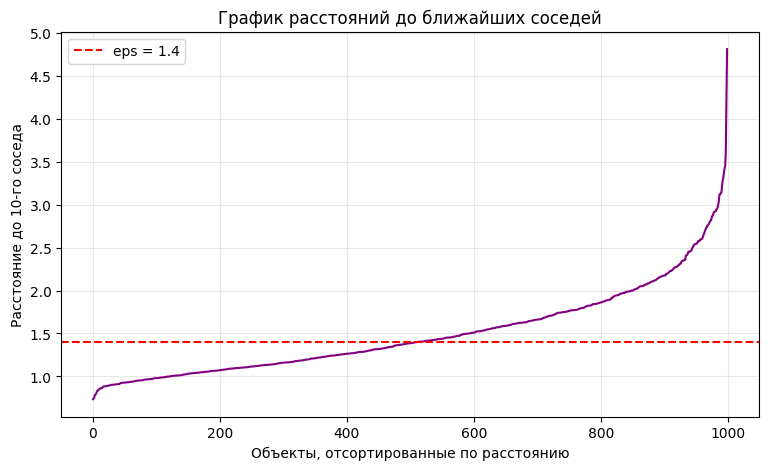

In [25]:
# Количество соседей соответствует будущему min_samples
min_samples = 10

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_pca_df)

distances, indices = neighbors_fit.kneighbors(X_pca_df)

# Берём расстояние до десятого соседа
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances, color='purple')
plt.axhline(y=1.4, color='red', linestyle='--', label='eps = 1.4')

plt.title('График расстояний до ближайших соседей')
plt.xlabel('Объекты, отсортированные по расстоянию')
plt.ylabel('Расстояние до 10-го соседа')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Выбор параметров DBSCAN

In [38]:
eps_values = [1.2, 1.4, 1.6, 1.8, 2.0]
min_samples_values = [3, 5, 10]

dbscan_results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_pca_df)

        # Количество кластеров без учёта шума (-1)
        unique_clusters = set(labels)
        n_clusters = len(unique_clusters) - (1 if -1 in unique_clusters else 0)

        # Доля точек, которые DBSCAN посчитал шумом
        noise_share = (labels == -1).mean() * 100

        # Silhouette считаем только для объектов, не являющихся шумом
        mask = labels != -1

        if n_clusters >= 2 and mask.sum() > n_clusters:
            silhouette = silhouette_score(
                X_pca_df[mask],
                labels[mask]
            )
        else:
            silhouette = np.nan

        dbscan_results.append({
            'eps': eps,
            'min_samples': min_samples,
            'Количество кластеров': n_clusters,
            'Доля шума, %': round(noise_share, 1),
            'Silhouette': round(silhouette, 3)
        })

dbscan_table = pd.DataFrame(dbscan_results)
dbscan_table

,eps,min_samples,Количество кластеров,"Доля шума, %",Silhouette
0,1.2,3,13,21.8,0.094
1,1.2,5,8,30.5,0.085
2,1.2,10,3,45.0,0.152
3,1.4,3,14,12.3,0.051
4,1.4,5,7,17.8,0.108
5,1.4,10,3,28.4,0.233
6,1.6,3,4,7.4,0.133
7,1.6,5,5,10.5,0.116
8,1.6,10,2,17.9,0.193
9,1.8,3,7,3.8,0.128


Итоговая модель DBSCAN

In [27]:
dbscan = DBSCAN(
    eps=1.4,
    min_samples=10
)

dbscan_labels = dbscan.fit_predict(X_pca_df)

df_dbscan = df.copy()
df_dbscan['DBSCAN_cluster'] = dbscan_labels

df_dbscan['DBSCAN_cluster'].value_counts().sort_index()

,count
DBSCAN_cluster,
-1,284
0,512
1,179
2,25


График

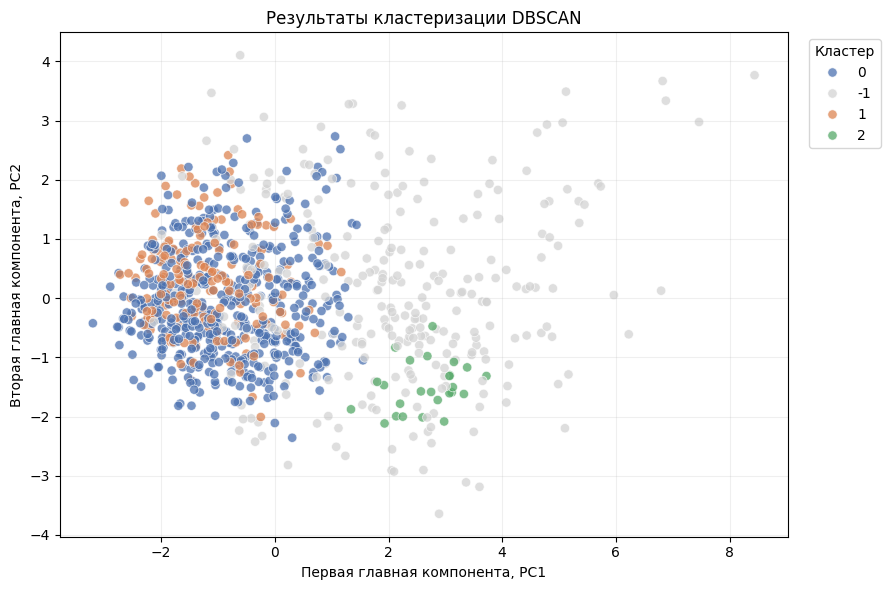

In [28]:
plot_dbscan = X_pca_df.copy()
plot_dbscan['Кластер'] = dbscan_labels.astype(str)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=plot_dbscan,
    x='PC1',
    y='PC2',
    hue='Кластер',
    palette={
        '-1': 'lightgray',
        '0': '#4C72B0',
        '1': '#DD8452',
        '2': '#55A868'
    },
    s=45,
    alpha=0.75
)

plt.title('Результаты кластеризации DBSCAN')
plt.xlabel('Первая главная компонента, PC1')
plt.ylabel('Вторая главная компонента, PC2')
plt.legend(title='Кластер', bbox_to_anchor=(1.02, 1))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Подготовка данных

In [29]:
# Заполняем пропуски для построения профилей
df_dbscan['Membership'] = (
    df_dbscan['Membership'].fillna('Unknown')
)

df_dbscan['Time_Spent_per_Visit_min'] = (
    df_dbscan['Time_Spent_per_Visit_min']
    .fillna(df_dbscan['Time_Spent_per_Visit_min'].mean())
)

df_dbscan['Avg_Purchase_Value_USD'] = (
    df_dbscan['Avg_Purchase_Value_USD']
    .fillna(df_dbscan['Avg_Purchase_Value_USD'].median())
)

Таблица характеристик

In [30]:
dbscan_profile_columns = [
    'Annual_Income_kUSD',
    'Visits_per_Month',
    'Pages_Visited_per_Session',
    'Time_Spent_per_Visit_min',
    'Previous_Purchases',
    'Avg_Purchase_Value_USD',
    'Total_Purchase_Value_USD',
    'Made_Purchase_Last_Month'
]

dbscan_profile = (
    df_dbscan
    .groupby('DBSCAN_cluster')[dbscan_profile_columns]
    .mean()
    .round(2)
)

dbscan_profile['Количество клиентов'] = (
    df_dbscan.groupby('DBSCAN_cluster').size()
)

dbscan_profile = dbscan_profile.rename(columns={
    'Annual_Income_kUSD': 'Средний доход',
    'Visits_per_Month': 'Посещений в месяц',
    'Pages_Visited_per_Session': 'Страниц за сессию',
    'Time_Spent_per_Visit_min': 'Время визита',
    'Previous_Purchases': 'Предыдущие покупки',
    'Avg_Purchase_Value_USD': 'Средний чек',
    'Total_Purchase_Value_USD': 'Общая сумма покупок',
    'Made_Purchase_Last_Month': 'Доля покупателей'
})

dbscan_profile['Доля покупателей'] = (
    dbscan_profile['Доля покупателей'] * 100
).round(1)

dbscan_profile

,Средний доход,Посещений в месяц,Страниц за сессию,Время визита,Предыдущие покупки,Средний чек,Общая сумма покупок,Доля покупателей,Количество клиентов
DBSCAN_cluster,,,,,,,,,
-1,72.13,6.51,6.38,10.33,3.18,57.84,191.09,28.0,284
0,52.88,4.15,3.80,8.32,1.10,35.34,49.29,13.0,512
1,51.17,3.88,3.94,7.72,0.84,33.73,38.44,9.0,179
2,77.09,7.48,6.84,15.30,3.12,29.42,100.93,40.0,25


Проверка подписки и платформы

In [31]:
dbscan_membership = pd.crosstab(
    df_dbscan['DBSCAN_cluster'],
    df_dbscan['Membership'],
    normalize='index'
).round(2)

dbscan_platform = pd.crosstab(
    df_dbscan['DBSCAN_cluster'],
    df_dbscan['Platform'],
    normalize='index'
).round(2)

display(dbscan_membership)
display(dbscan_platform)

Membership,Basic,Premium,Unknown
DBSCAN_cluster,,,
-1,0.29,0.56,0.15
0,0.40,0.01,0.58
1,0.30,0.00,0.70
2,0.00,1.00,0.00


Platform,Desktop,Mobile,Tablet
DBSCAN_cluster,,,
-1,0.34,0.61,0.05
0,0.00,1.00,0.00
1,0.91,0.00,0.09
2,0.00,1.00,0.00


Названия групп

In [32]:
dbscan_names = {
    -1: 'Неоднородные клиенты',
    0: 'Обычные мобильные клиенты',
    1: 'Малоактивные desktop-клиенты',
    2: 'Активные мобильные Premium-клиенты'
}

df_dbscan['Название группы'] = (
    df_dbscan['DBSCAN_cluster'].map(dbscan_names)
)

df_dbscan[
    ['DBSCAN_cluster', 'Название группы']
].drop_duplicates().sort_values('DBSCAN_cluster')

,DBSCAN_cluster,Название группы
4,-1,Неоднородные клиенты
0,0,Обычные мобильные клиенты
17,1,Малоактивные desktop-клиенты
55,2,Активные мобильные Premium-клиенты


Таблица соответствия кластеров

In [33]:
cluster_comparison = pd.crosstab(
    df_kmeans['KMeans_cluster'],
    df_dbscan['DBSCAN_cluster'],
    rownames=['Кластер KMeans'],
    colnames=['Кластер DBSCAN'],
    margins=True
)

cluster_comparison

Кластер DBSCAN,-1,0,1,2,All
Кластер KMeans,,,,,
0,15,294,0,0,309
1,27,214,0,0,241
2,75,1,0,0,76
3,57,0,179,0,236
4,110,3,0,25,138
All,284,512,179,25,1000


Общая таблица сравнения методов

In [34]:
methods_comparison = pd.DataFrame({
    'Метод': ['KMeans', 'DBSCAN'],
    'Количество кластеров': [5, 3],
    'Доля шума, %': [0, 28.4],
    'Silhouette': [0.198, 0.233]
})

methods_comparison

,Метод,Количество кластеров,"Доля шума, %",Silhouette
0,KMeans,5,0.0,0.198
1,DBSCAN,3,28.4,0.233


Таблица предпочтений товаров

In [35]:
product_preferences = pd.crosstab(
    df_kmeans['Название кластера'],
    df_kmeans['Product_Preference'],
    normalize='index'
).mul(100).round(1)

product_preferences

Product_Preference,Apparel,Beauty,Books,Electronics,Home & Kitchen,Sports
Название кластера,,,,,,
Активные Basic-клиенты,21.6,16.2,11.2,16.2,17.8,17.0
Активные Premium-клиенты,23.9,10.9,19.6,6.5,20.3,18.8
Малоактивные desktop-клиенты,19.1,16.1,14.4,15.7,15.7,19.1
Малоактивные мобильные клиенты,16.8,16.2,13.6,17.5,19.7,16.2
Самые ценные покупатели,10.5,2.6,1.3,52.6,15.8,17.1


Упрощенная табличка

In [36]:
top_products = product_preferences.idxmax(axis=1)
top_product_share = product_preferences.max(axis=1)

segment_products = pd.DataFrame({
    'Популярная категория': top_products,
    'Доля клиентов, %': top_product_share
})

segment_products

,Популярная категория,"Доля клиентов, %"
Название кластера,,
Активные Basic-клиенты,Apparel,21.6
Активные Premium-клиенты,Apparel,23.9
Малоактивные desktop-клиенты,Apparel,19.1
Малоактивные мобильные клиенты,Home & Kitchen,19.7
Самые ценные покупатели,Electronics,52.6
